# A2: Hand gesture recognition: real vs real + synthetic (Wan2.1)
Ожидаемая структура папок на Google Drive (`MyDrive/cv_a2/`):
```
real/train/<class>/*.jpg      # ваши кадры из A1 (256x256, как в A1)
real/val/<class>/*.jpg
real/test/<class>/*.jpg
real_env_test/<env>/<class>/*.jpg   # (необязательно) новые реальные видео по окружениям: dark, outdoor, ...
synthetic_clips/*.mp4         # клипы из генерации (имя начинается с thumbs / fist / peace / stop)
```
Классы: fist, peace, stop, thumbs_up. Если ваша структура другая, поправьте пути в ячейке «Конфиг».

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Конфиг

In [2]:
import os, glob, random, json, time, copy
import numpy as np
from pathlib import Path

SEED = 42
CLASSES = ["fist", "peace", "stop", "thumbs_up"]
BASE = "/content/drive/MyDrive/cv_a2"
REAL_ROOT = f"{BASE}/real"                 # real/{train,val,test}/<class>/
ENV_TEST_ROOT = f"{BASE}/real_env_test"    # real_env_test/<env>/<class>/  (необязательно)
CLIPS_DIR = f"{BASE}/synthetic_clips"
SYNTH_ROOT = "/content/synth_frames"
OUT_DIR = f"{BASE}/results"
os.makedirs(OUT_DIR, exist_ok=True)

# клипы, которые вы вручную забраковали (по имени файла без .mp4), например ["stop_dark_s0"]
EXCLUDE = ["thumbs_side_wood_warm_s0", "thumbs_side_beige_soft_s0", "thumbs_side_dark_s0", "stop_beige_spread_s0", "stop_dark_s0", "peace_dark_s0", "fist_wood_warm_s0", "fist_outdoor_s0"]

## 2. Кадры из синтетических клипов
Как в A1: отбрасываем начало клипа (первые 8 кадров, там «дёрганье»), берём каждый 4-й кадр, квадратная обрезка со смещением 20% по вертикали, ресайз до 256x256.
Перед обучением просмотрите папку `/content/synth_frames` и удалите кадры с кривыми руками.

In [3]:
import cv2

def class_of(fname):
    n = Path(fname).name.lower()
    for key, c in [("thumbs", "thumbs_up"), ("fist", "fist"), ("peace", "peace"), ("stop", "stop")]:
        if n.startswith(key):
            return c
    return None

def crop_square(img, v_offset=0.2):
    h, w = img.shape[:2]
    s = min(h, w)
    y0 = int((h - s) * v_offset)
    x0 = int((w - s) / 2)
    return img[y0:y0 + s, x0:x0 + s]

def extract_frames(skip_first=8, step=4, size=256):
    n_saved = 0
    for p in sorted(glob.glob(f"{CLIPS_DIR}/*.mp4")):
        stem = Path(p).stem
        c = class_of(p)
        if c is None or stem in EXCLUDE:
            continue
        out = Path(SYNTH_ROOT) / c
        out.mkdir(parents=True, exist_ok=True)
        cap = cv2.VideoCapture(p)
        i = 0
        while True:
            ok, fr = cap.read()
            if not ok:
                break
            if i >= skip_first and (i - skip_first) % step == 0:
                fr = cv2.resize(crop_square(fr), (size, size))
                cv2.imwrite(str(out / f"{stem}_f{i:03d}.jpg"), fr)
                n_saved += 1
            i += 1
        cap.release()
    return n_saved

print("Сохранено кадров:", extract_frames())
for c in CLASSES:
    print(c, len(glob.glob(f"{SYNTH_ROOT}/{c}/*.jpg")))

Сохранено кадров: 14
fist 0
peace 7
stop 0
thumbs_up 7


In [9]:
import shutil
os.makedirs(f"{BASE}/results/synthetic_examples", exist_ok=True)
for c in CLASSES:
    files = sorted(glob.glob(f"{SYNTH_ROOT}/{c}/*.jpg"))[::3][:3]
    for f in files:
        shutil.copy(f, f"{BASE}/results/synthetic_examples/")
print(os.listdir(f"{BASE}/results/synthetic_examples"))

['peace_outdoor_s0_f008.jpg', 'peace_outdoor_s0_f020.jpg', 'peace_outdoor_s0_f032.jpg', 'thumbs_up_wall_light_s0_f008.jpg', 'thumbs_up_wall_light_s0_f020.jpg', 'thumbs_up_wall_light_s0_f032.jpg']


fist : нет синтетических кадров


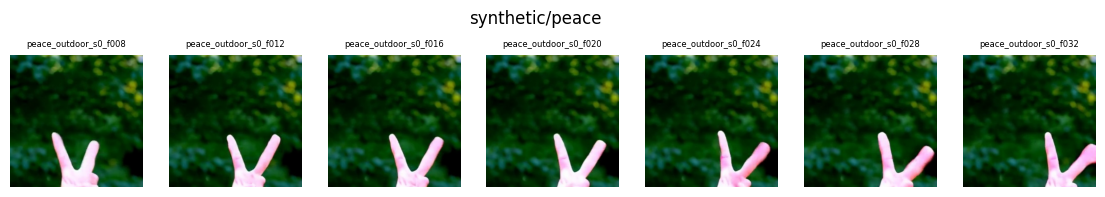

stop : нет синтетических кадров


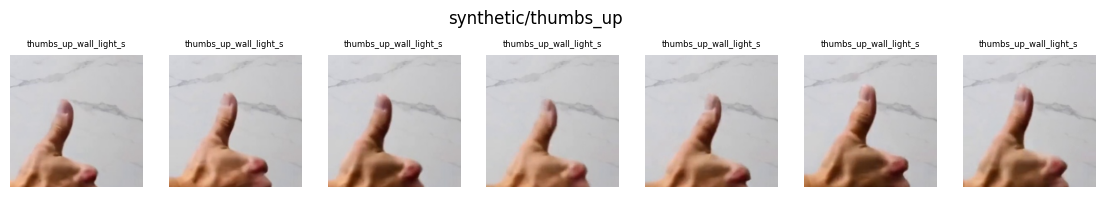

In [8]:
import matplotlib.pyplot as plt
from PIL import Image
for c in CLASSES:
    files = sorted(glob.glob(f"{SYNTH_ROOT}/{c}/*.jpg"))
    if not files:
        print(c, ": нет синтетических кадров"); continue
    pick = files[::max(1, len(files) // 8)][:8]
    fig, ax = plt.subplots(1, len(pick), figsize=(2 * len(pick), 2.3))
    for a, p in zip(np.atleast_1d(ax), pick):
        a.imshow(Image.open(p)); a.axis("off"); a.set_title(Path(p).stem[:22], fontsize=6)
    plt.suptitle(f"synthetic/{c}"); plt.show()

## 3. Данные и модель (как в A1: MobileNetV2, 2 стадии)

In [4]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import transforms as T, models
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(MEAN, STD)])
aug_tf = T.Compose([T.RandomResizedCrop(224, scale=(0.75, 1.0)), T.RandomHorizontalFlip(),
                    T.RandomRotation(15), T.ColorJitter(0.3, 0.3, 0.2, 0.02),
                    T.ToTensor(), T.Normalize(MEAN, STD)])

class FolderDS(Dataset):
    def __init__(self, root, tf):
        self.tf = tf
        self.items = []
        for ci, c in enumerate(CLASSES):
            files = []
            for ext in ("jpg", "jpeg", "png"):
                files += glob.glob(f"{root}/{c}/*.{ext}")
            self.items += [(p, ci) for p in sorted(files)]
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        return self.tf(Image.open(p).convert("RGB")), y

def build_model():
    m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(m.last_channel, len(CLASSES))
    for mod in m.modules():
        if isinstance(mod, nn.ReLU6):
            mod.inplace = False      # нужно для Grad-CAM
    return m

crit = nn.CrossEntropyLoss()

def run_epoch(model, loader, opt=None):
    train = opt is not None
    model.train(train)
    n = correct = 0
    loss_sum = 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = crit(out, y)
            if train:
                opt.zero_grad()
                loss.backward()
                opt.step()
            n += len(y)
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
    return loss_sum / n, correct / n

def train_model(train_ds, val_ds, epochs1=5, epochs2=5, seed=SEED):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    model = build_model().to(device)
    tl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
    vl = DataLoader(val_ds, batch_size=32, num_workers=2)
    best = {"acc": -1, "state": None}
    hist = []

    def fit(params, lr, epochs, stage):
        opt = torch.optim.Adam(params, lr=lr)
        for ep in range(epochs):
            trl, tra = run_epoch(model, tl, opt)
            vll, vla = run_epoch(model, vl)
            hist.append(dict(stage=stage, train_loss=trl, train_acc=tra, val_loss=vll, val_acc=vla))
            print(f"[{stage}] ep{ep+1}: train {tra:.3f} / val {vla:.3f}")
            if vla > best["acc"]:
                best["acc"] = vla
                best["state"] = copy.deepcopy(model.state_dict())

    for p in model.features.parameters():
        p.requires_grad = False
    fit(model.classifier.parameters(), 1e-3, epochs1, "head")
    for p in model.features[14:].parameters():
        p.requires_grad = True
    params = list(model.features[14:].parameters()) + list(model.classifier.parameters())
    fit(params, 1e-4, epochs2, "finetune")
    model.load_state_dict(best["state"])
    return model, hist

## 4. Оценка

In [5]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

@torch.no_grad()
def predict(model, ds):
    model.eval()
    ys, ps = [], []
    for x, y in DataLoader(ds, batch_size=64, num_workers=2):
        ps += model(x.to(device)).argmax(1).cpu().tolist()
        ys += y.tolist()
    return np.array(ys), np.array(ps)

def evaluate(model, ds):
    if len(ds) == 0:
        return None
    y, p = predict(model, ds)
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    _, rec_cls, _, _ = precision_recall_fscore_support(y, p, labels=range(len(CLASSES)), zero_division=0)
    return dict(n=len(y), acc=accuracy_score(y, p), precision=pr, recall=rc, f1=f1,
                recall_per_class={c: float(r) for c, r in zip(CLASSES, rec_cls)},
                cm=confusion_matrix(y, p, labels=range(len(CLASSES))).tolist())

def evaluate_envs(model):
    res = {}
    if not os.path.isdir(ENV_TEST_ROOT):
        return res
    for env in sorted(os.listdir(ENV_TEST_ROOT)):
        r = evaluate(model, FolderDS(f"{ENV_TEST_ROOT}/{env}", eval_tf))
        if r:
            res[env] = r
    return res

## 5. Эксперименты (с абляцией)
- `A1_real_noaug`: воспроизведение лучшей модели A1 (только реальные кадры, без аугментации)
- `real+synth_noaug`: реальные + синтетические кадры в train
- `real+synth_aug`: то же, но с аугментацией (по желанию; поставьте `True` в `RUN_AUG`)

Синтетика попадает **только в train**. Val и test остаются реальными.

In [6]:
RUN_AUG = False

real_train = FolderDS(f"{REAL_ROOT}/train", eval_tf)
real_val = FolderDS(f"{REAL_ROOT}/val", eval_tf)
real_test = FolderDS(f"{REAL_ROOT}/test", eval_tf)
synth_ds = FolderDS(SYNTH_ROOT, eval_tf)
print("real train/val/test:", len(real_train), len(real_val), len(real_test), "| synthetic:", len(synth_ds))
share = len(synth_ds) / max(1, len(synth_ds) + len(real_train))
print(f"Доля синтетики в обучающей выборке: {share:.1%}")

configs = {"A1_real_noaug": ConcatDataset([real_train]),
           "real+synth_noaug": ConcatDataset([real_train, synth_ds])}
if RUN_AUG:
    configs["real+synth_aug"] = ConcatDataset([FolderDS(f"{REAL_ROOT}/train", aug_tf),
                                               FolderDS(SYNTH_ROOT, aug_tf)])

results, models_, hists = {}, {}, {}
for name, tr in configs.items():
    print("=" * 20, name, f"(train size {len(tr)})")
    model, hist = train_model(tr, real_val)
    models_[name], hists[name] = model, hist
    torch.save(model.state_dict(), f"{OUT_DIR}/{name}.pt")
    results[name] = dict(test=evaluate(model, real_test), envs=evaluate_envs(model))
    print({k: round(v, 3) for k, v in results[name]["test"].items() if k in ("acc", "precision", "recall", "f1")})

json.dump(dict(results=results, hists=hists, synthetic_share=share), open(f"{OUT_DIR}/results.json", "w"), indent=1)

real train/val/test: 573 172 181 | synthetic: 14
Доля синтетики в обучающей выборке: 2.4%
==================== A1_real_noaug (train size 573)
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 123MB/s]


[head] ep1: train 0.637 / val 0.657
[head] ep2: train 0.909 / val 0.884
[head] ep3: train 0.944 / val 0.843
[head] ep4: train 0.951 / val 0.849
[head] ep5: train 0.963 / val 0.930
[finetune] ep1: train 0.983 / val 0.977
[finetune] ep2: train 1.000 / val 0.988
[finetune] ep3: train 1.000 / val 0.988
[finetune] ep4: train 1.000 / val 0.983
[finetune] ep5: train 1.000 / val 0.983
{'acc': 0.989, 'precision': 0.988, 'recall': 0.99, 'f1': 0.989}
==================== real+synth_noaug (train size 587)


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x789a09ba4ae0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1656, in _shutdown_workers
    w.join(timeout=_utils.MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.13/multiprocessing/process.py", line 149, in join
    res = self._popen.wait(timeout)
  File "/usr/lib/python3.13/multiprocessing/popen_fork.py", line 41, in wait
    if not wait([self.sentinel], timeout):
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 1174, in wait
    ready = selector.select(timeout)
  File "/usr/lib/python3.13/selectors.py", line 398, in select
    fd_event_list = self._selector.poll(timeout)
KeyboardInterrupt: 


KeyboardInterrupt: 

In [9]:
import pandas as pd
rows = []
for name, r in results.items():
    t = r["test"]
    rows.append(dict(model=name, test_acc=t["acc"], precision=t["precision"], recall=t["recall"], f1=t["f1"],
                     thumbs_up_recall=t["recall_per_class"]["thumbs_up"],
                     stop_recall=t["recall_per_class"]["stop"]))
df = pd.DataFrame(rows).round(3)
df.to_csv(f"{OUT_DIR}/table_test.csv", index=False)
display(df)

env_rows = []
for name, r in results.items():
    for env, e in r["envs"].items():
        env_rows.append(dict(model=name, env=env, n=e["n"], acc=e["acc"], f1=e["f1"]))
if env_rows:
    env_df = pd.DataFrame(env_rows).round(3)
    env_df.to_csv(f"{OUT_DIR}/table_envs.csv", index=False)
    display(env_df.pivot(index="env", columns="model", values="acc"))

,model,test_acc,precision,recall,f1,thumbs_up_recall,stop_recall
0,A1_real_noaug,0.989,0.988,0.990,0.989,0.98,0.98
1,real+synth_noaug,0.994,0.994,0.995,0.995,0.98,1.00


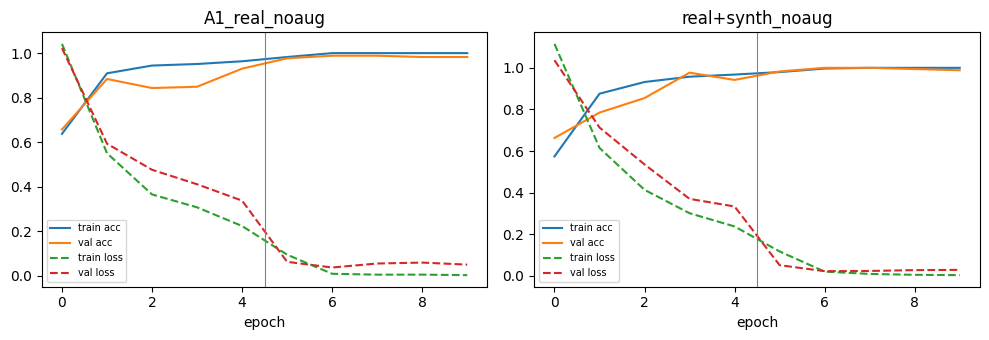

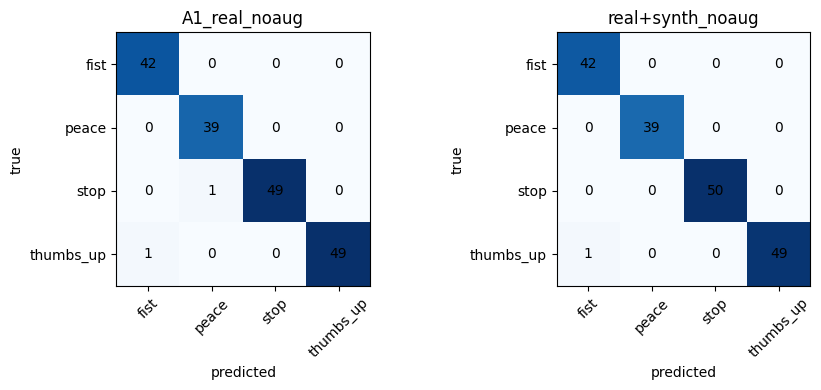

In [10]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(hists), figsize=(5 * len(hists), 3.5), squeeze=False)
for ax, (name, h) in zip(axes[0], hists.items()):
    ax.plot([e["train_acc"] for e in h], label="train acc")
    ax.plot([e["val_acc"] for e in h], label="val acc")
    ax.plot([e["train_loss"] for e in h], "--", label="train loss")
    ax.plot([e["val_loss"] for e in h], "--", label="val loss")
    ax.axvline(4.5, color="gray", lw=0.8)
    ax.set_title(name); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=150); plt.show()

# матрицы ошибок
fig, axes = plt.subplots(1, len(results), figsize=(4.5 * len(results), 4), squeeze=False)
for ax, (name, r) in zip(axes[0], results.items()):
    cm = np.array(r["test"]["cm"])
    ax.imshow(cm, cmap="Blues")
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=45)
    ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
    ax.set_title(name); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrices.png", dpi=150); plt.show()

In [11]:
import cv2, shutil
ENV_VID_DIR = f"{BASE}/env_videos"

def class_of(fname):
    n = Path(fname).name.lower()
    for key, c in [("thumbs", "thumbs_up"), ("fist", "fist"), ("peace", "peace"), ("stop", "stop")]:
        if n.startswith(key):
            return c
    return None

def crop_square(img, v_offset=0.2):
    h, w = img.shape[:2]; s = min(h, w)
    y0, x0 = int((h - s) * v_offset), int((w - s) / 2)
    return img[y0:y0 + s, x0:x0 + s]

def extract_env_video(p, out_dir, skip_start=2.0, skip_end=1.5, step=4, max_frames=50,
                      size=256, min_diff=3.0, min_hand_frac=0.10, diff_thr=30):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    cap = cv2.VideoCapture(p)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    def prep(fr):
        fr = cv2.resize(crop_square(fr), (size, size))
        return fr, cv2.GaussianBlur(cv2.resize(fr, (64, 64)), (5, 5), 0).astype("float32")
    ok, f0 = cap.read()
    if not ok:
        return 0
    _, bg = prep(f0)
    saved, last = 0, None
    for i in range(int(skip_start * fps), total - int(skip_end * fps), step):
        if saved >= max_frames:
            break
        cap.set(cv2.CAP_PROP_POS_FRAMES, i)
        ok, fr = cap.read()
        if not ok:
            break
        fr, col = prep(fr)
        if (np.abs(col - bg).max(axis=2) > diff_thr).mean() < min_hand_frac:
            continue
        gray = cv2.resize(cv2.cvtColor(col.astype("uint8"), cv2.COLOR_BGR2GRAY), (32, 32)).astype("float32")
        if last is not None and np.abs(gray - last).mean() < min_diff:
            continue
        last = gray
        cv2.imwrite(str(out_dir / f"{Path(p).stem}_f{i:05d}.jpg"), fr)
        saved += 1
    cap.release()
    return saved

shutil.rmtree(ENV_TEST_ROOT, ignore_errors=True)
rows = []
for p in sorted(glob.glob(f"{ENV_VID_DIR}/*/*.mp4")):
    env, c = Path(p).parent.name, class_of(p)
    if c is None:
        print("пропуск:", p); continue
    out = Path(ENV_TEST_ROOT) / env / c
    n = extract_env_video(p, out)
    if n < 15:                                   # фильтр руки не сработал, режем без него
        for f in out.glob(f"{Path(p).stem}_f*.jpg"):
            f.unlink()
        n = extract_env_video(p, out, min_hand_frac=0.0)
    rows.append(dict(env=env, cls=c, frames=n))
cnt = pd.DataFrame(rows)
display(cnt.pivot(index="env", columns="cls", values="frames"))

cls,fist,peace,stop,thumbs_up
env,,,,
dark,4.0,9.0,NaN,NaN
outdoor,47.0,50.0,50.0,50.0
person2,4.0,9.0,16.0,32.0


In [12]:
if "models_" not in globals() or not models_:
    models_ = {}
    for name in ["A1_real_noaug", "real+synth_noaug"]:
        m = build_model().to(device)
        m.load_state_dict(torch.load(f"{OUT_DIR}/{name}.pt", map_location=device))
        models_[name] = m.eval()

rows = []
for env in sorted(os.listdir(ENV_TEST_ROOT)):
    ds = FolderDS(f"{ENV_TEST_ROOT}/{env}", eval_tf)
    for mname, m in models_.items():
        r = evaluate(m, ds)
        if r:
            rows.append(dict(env=env, model=mname, n=r["n"], acc=r["acc"], f1=r["f1"],
                             thumbs_up_recall=r["recall_per_class"]["thumbs_up"]))
env_df = pd.DataFrame(rows).round(3)
env_df.to_csv(f"{OUT_DIR}/table_envs.csv", index=False)
display(env_df)
display(env_df.pivot(index="env", columns="model", values="acc"))

,env,model,n,acc,f1,thumbs_up_recall
0,dark,A1_real_noaug,13,0.308,0.235,0.000
1,dark,real+synth_noaug,13,0.308,0.235,0.000
2,outdoor,A1_real_noaug,197,0.386,0.284,1.000
3,outdoor,real+synth_noaug,197,0.695,0.617,1.000
4,person2,A1_real_noaug,61,0.738,0.733,0.562
5,person2,real+synth_noaug,61,0.902,0.870,0.812


model,A1_real_noaug,real+synth_noaug
env,,
dark,0.308,0.308
outdoor,0.386,0.695
person2,0.738,0.902


In [13]:
weak = cnt[cnt.frames < 40]
print(weak)
for _, r in weak.iterrows():
    key = "thumbs" if r.cls == "thumbs_up" else r.cls
    for p in glob.glob(f"{ENV_VID_DIR}/{r.env}/{key}*.mp4"):
        out = Path(ENV_TEST_ROOT) / r.env / r.cls
        for f in out.glob(f"{Path(p).stem}_f*.jpg"):
            f.unlink()
        n = extract_env_video(p, out, min_hand_frac=0.0, min_diff=0.7)
        print(r.env, r.cls, Path(p).name, "->", n)

       env        cls  frames
0     dark       fist       4
1     dark      peace       9
6  person2       fist       4
7  person2      peace       9
8  person2       stop      16
9  person2  thumbs_up      32
dark fist fist_1.mp4 -> 40
dark peace peace_1.mp4 -> 50
person2 fist fist_3.mp4 -> 45
person2 peace peace_3.mp4 -> 50
person2 stop stop_3.mp4 -> 50
person2 thumbs_up thumbs_up_3.mp4 -> 50


In [14]:
for env in sorted(os.listdir(ENV_TEST_ROOT)):
    ds = FolderDS(f"{ENV_TEST_ROOT}/{env}", eval_tf)
    for mname, m in models_.items():
        r = evaluate(m, ds)
        if r:
            print(f"\n{env} | {mname} | acc {r['acc']:.3f}  (строки = истина, столбцы = предсказание: {CLASSES})")
            print(np.array(r["cm"]))


dark | A1_real_noaug | acc 0.433  (строки = истина, столбцы = предсказание: ['fist', 'peace', 'stop', 'thumbs_up'])
[[39  0  0  1]
 [47  0  0  3]
 [ 0  0  0  0]
 [ 0  0  0  0]]

dark | real+synth_noaug | acc 0.433  (строки = истина, столбцы = предсказание: ['fist', 'peace', 'stop', 'thumbs_up'])
[[39  0  0  1]
 [50  0  0  0]
 [ 0  0  0  0]
 [ 0  0  0  0]]

outdoor | A1_real_noaug | acc 0.386  (строки = истина, столбцы = предсказание: ['fist', 'peace', 'stop', 'thumbs_up'])
[[ 0  0  0 47]
 [ 0  0  0 50]
 [ 0  0 26 24]
 [ 0  0  0 50]]

outdoor | real+synth_noaug | acc 0.695  (строки = истина, столбцы = предсказание: ['fist', 'peace', 'stop', 'thumbs_up'])
[[ 0  0  0 47]
 [ 0 44  1  5]
 [ 0  2 43  5]
 [ 0  0  0 50]]

person2 | A1_real_noaug | acc 0.723  (строки = истина, столбцы = предсказание: ['fist', 'peace', 'stop', 'thumbs_up'])
[[45  0  0  0]
 [ 0 34  1 15]
 [ 0  1 48  1]
 [33  0  3 14]]

person2 | real+synth_noaug | acc 0.831  (строки = истина, столбцы = предсказание: ['fist', 'pe

In [15]:
cfgs = {
 "real_noaug":       ConcatDataset([FolderDS(f"{REAL_ROOT}/train", eval_tf)]),
 "real_aug":         ConcatDataset([FolderDS(f"{REAL_ROOT}/train", aug_tf)]),
 "real+synth_noaug": ConcatDataset([FolderDS(f"{REAL_ROOT}/train", eval_tf), FolderDS(SYNTH_ROOT, eval_tf)]),
 "real+synth_aug":   ConcatDataset([FolderDS(f"{REAL_ROOT}/train", aug_tf), FolderDS(SYNTH_ROOT, aug_tf)]),
}
env_sets = {e: FolderDS(f"{ENV_TEST_ROOT}/{e}", eval_tf) for e in sorted(os.listdir(ENV_TEST_ROOT))}

rows = []
for name, tr in cfgs.items():
    for seed in [0, 1, 2]:
        print("=" * 10, name, "seed", seed)
        model, _ = train_model(tr, real_val, seed=seed)
        row = dict(config=name, seed=seed, test_acc=evaluate(model, real_test)["acc"])
        for e, ds in env_sets.items():
            r = evaluate(model, ds)
            row[f"acc_{e}"] = r["acc"] if r else np.nan
        rows.append(row)
        pd.DataFrame(rows).to_csv(f"{OUT_DIR}/multiseed_raw.csv", index=False)

raw = pd.DataFrame(rows)
summary = raw.drop(columns="seed").groupby("config").agg(["mean", "std"]).round(3)
summary.to_csv(f"{OUT_DIR}/multiseed_summary.csv")
display(summary)

========== real_noaug seed 0
[head] ep1: train 0.572 / val 0.692
[head] ep2: train 0.864 / val 0.890
[head] ep3: train 0.937 / val 0.901
[head] ep4: train 0.934 / val 0.872
[head] ep5: train 0.953 / val 0.895
[finetune] ep1: train 0.976 / val 0.983
[finetune] ep2: train 1.000 / val 0.977
[finetune] ep3: train 1.000 / val 0.983
[finetune] ep4: train 1.000 / val 0.988
[finetune] ep5: train 1.000 / val 0.977
========== real_noaug seed 1
[head] ep1: train 0.492 / val 0.488
[head] ep2: train 0.852 / val 0.779
[head] ep3: train 0.920 / val 0.791
[head] ep4: train 0.960 / val 0.762
[head] ep5: train 0.946 / val 0.919
[finetune] ep1: train 0.974 / val 0.994
[finetune] ep2: train 1.000 / val 0.988
[finetune] ep3: train 1.000 / val 0.977
[finetune] ep4: train 1.000 / val 0.977
[finetune] ep5: train 1.000 / val 0.983
========== real_noaug seed 2
[head] ep1: train 0.572 / val 0.605
[head] ep2: train 0.859 / val 0.820
[head] ep3: train 0.925 / val 0.895
[head] ep4: train 0.939 / val 0.814
[head] ep

test_acc        acc_dark        acc_outdoor         \
                     mean    std     mean    std        mean    std   
config                                                                
real+synth_aug      0.987  0.013    0.881  0.064       0.799  0.102   
real+synth_noaug    0.991  0.003    0.430  0.017       0.540  0.043   
real_aug            0.994  0.010    0.874  0.061       0.643  0.147   
real_noaug          0.989  0.000    0.337  0.167       0.374  0.013   

                 acc_person2         
                        mean    std  
config                               
real+synth_aug         0.870  0.060  
real+synth_noaug       0.793  0.030  
real_aug               0.882  0.015  
real_noaug             0.721  0.018

In [9]:
# --- проверки
assert len(glob.glob(f"{SYNTH_ROOT}/*/*.jpg")) > 0, "Нет синтетических кадров: запустите ячейку раздела 2"

real_val = FolderDS(f"{REAL_ROOT}/val", eval_tf)
real_test = FolderDS(f"{REAL_ROOT}/test", eval_tf)
final_train = ConcatDataset([FolderDS(f"{REAL_ROOT}/train", aug_tf),
                             FolderDS(SYNTH_ROOT, aug_tf)])
print("train:", len(final_train), "| val:", len(real_val), "| test:", len(real_test))

# --- обучение и сохранение
final_model, final_hist = train_model(final_train, real_val, seed=0)
torch.save(final_model.state_dict(), f"{OUT_DIR}/final_real+synth_aug.pt")
if "models_" not in globals():
    models_ = {}
models_["final_real+synth_aug"] = final_model

# --- метрики финальной модели на тесте и по окружениям
r = evaluate(final_model, real_test)
print({k: round(v, 3) for k, v in r.items() if k in ("acc", "precision", "recall", "f1")})
for env in sorted(os.listdir(ENV_TEST_ROOT)):
    re_ = evaluate(final_model, FolderDS(f"{ENV_TEST_ROOT}/{env}", eval_tf))
    if re_:
        print(env, "acc", round(re_["acc"], 3), "n", re_["n"])

# --- latency (только прогон модели, 1 изображение 224x224)
@torch.no_grad()
def latency_ms(model, dev, n=100):
    m = copy.deepcopy(model).to(dev).eval()
    x = torch.randn(1, 3, 224, 224, device=dev)
    for _ in range(10):
        m(x)
    if dev == "cuda":
        torch.cuda.synchronize()
    t = time.time()
    for _ in range(n):
        m(x)
    if dev == "cuda":
        torch.cuda.synchronize()
    return (time.time() - t) / n * 1000

lat = {"cpu_ms": round(latency_ms(final_model, "cpu"), 2)}
if torch.cuda.is_available():
    lat["gpu_ms"] = round(latency_ms(final_model, "cuda"), 2)
    lat["gpu"] = torch.cuda.get_device_name(0)
print("latency:", lat)
json.dump(lat, open(f"{OUT_DIR}/latency.json", "w"))

train: 587 | val: 172 | test: 181
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 148MB/s]


[head] ep1: train 0.383 / val 0.459
[head] ep2: train 0.760 / val 0.715
[head] ep3: train 0.835 / val 0.890
[head] ep4: train 0.865 / val 0.831
[head] ep5: train 0.857 / val 0.826
[finetune] ep1: train 0.954 / val 0.977
[finetune] ep2: train 0.983 / val 1.000
[finetune] ep3: train 0.991 / val 1.000
[finetune] ep4: train 0.990 / val 0.971
[finetune] ep5: train 0.995 / val 1.000
{'acc': 0.994, 'precision': 0.994, 'recall': 0.995, 'f1': 0.995}
dark acc 0.844 n 90
outdoor acc 0.695 n 197
person2 acc 0.882 n 195
latency: {'cpu_ms': 43.59, 'gpu_ms': 5.56, 'gpu': 'Tesla T4'}


## 6. Latency (только прогон модели, 1 изображение 224x224)

In [7]:
@torch.no_grad()
def latency_ms(model, dev, n=100):
    m = copy.deepcopy(model).to(dev).eval()
    x = torch.randn(1, 3, 224, 224, device=dev)
    for _ in range(10):
        m(x)
    if dev == "cuda":
        torch.cuda.synchronize()
    t = time.time()
    for _ in range(n):
        m(x)
    if dev == "cuda":
        torch.cuda.synchronize()
    return (time.time() - t) / n * 1000

best_name = max(results, key=lambda k: results[k]["test"]["f1"])
best_model = models_[best_name]
lat = {"cpu_ms": latency_ms(best_model, "cpu")}
if torch.cuda.is_available():
    lat["gpu_ms"] = latency_ms(best_model, "cuda")
    lat["gpu"] = torch.cuda.get_device_name(0)
print("Лучшая по F1:", best_name, lat)
json.dump(lat, open(f"{OUT_DIR}/latency.json", "w"))

Лучшая по F1: A1_real_noaug {'cpu_ms': 25.661258697509766, 'gpu_ms': 5.47032356262207, 'gpu': 'Tesla T4'}


In [8]:
import matplotlib.pyplot as plt

def load_model(fname):
    m = build_model().to(device)
    m.load_state_dict(torch.load(f"{OUT_DIR}/{fname}", map_location=device))
    return m.eval()

final_model = load_model("final_real+synth_aug.pt")
base_model = load_model("A1_real_noaug.pt")

def gradcam(model, x):
    model.eval()
    store = {}
    layer = model.features[-1]
    def fwd_hook(m, i, o):
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))
    h = layer.register_forward_hook(fwd_hook)
    out = model(x.unsqueeze(0).to(device))
    cls = int(out.argmax(1))
    model.zero_grad()
    out[0, cls].backward()
    h.remove()
    w = store["g"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * store["a"]).sum(1, keepdim=True))
    cam = torch.nn.functional.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), cls

def show_gradcam(model, ds, n=8, title="", fname=None):
    idx = random.Random(0).sample(range(len(ds)), min(n, len(ds)))
    fig, axes = plt.subplots(2, len(idx), figsize=(2.2 * len(idx), 5), squeeze=False)
    for k, i in enumerate(idx):
        x, y = ds[i]
        cam, cls = gradcam(model, x)
        img = (x.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)).clip(0, 1)
        axes[0, k].imshow(img); axes[0, k].axis("off")
        axes[0, k].set_title(f"true: {CLASSES[y]}\npred: {CLASSES[cls]}", fontsize=8)
        axes[1, k].imshow(img); axes[1, k].imshow(cam, cmap="jet", alpha=0.45); axes[1, k].axis("off")
    plt.suptitle(title); plt.tight_layout()
    if fname:
        plt.savefig(f"{OUT_DIR}/{fname}", dpi=150)
    plt.show()

def subset_cls(root, cls):
    ds = FolderDS(root, eval_tf)
    keep = [i for i, (p, y) in enumerate(ds.items) if CLASSES[y] == cls]
    return torch.utils.data.Subset(ds, keep)

real_test = FolderDS(f"{REAL_ROOT}/test", eval_tf)

# 0) проверка: метрики загруженной финальной модели
r = evaluate(final_model, real_test)
print("final on test:", {k: round(v, 3) for k, v in r.items() if k in ("acc", "precision", "recall", "f1")})
for env in sorted(os.listdir(ENV_TEST_ROOT)):
    re_ = evaluate(final_model, FolderDS(f"{ENV_TEST_ROOT}/{env}", eval_tf))
    if re_:
        print(" ", env, "acc", round(re_["acc"], 3), "n", re_["n"])

# 1) обычные примеры на тесте
show_gradcam(final_model, real_test, n=8, title="Grad-CAM, final model, test", fname="gradcam_final_test.png")

# 2) где baseline ошибается: fist на улице (baseline vs final)
outdoor_fist = subset_cls(f"{ENV_TEST_ROOT}/outdoor", "fist")
show_gradcam(base_model, outdoor_fist, n=6, title="BASELINE: outdoor, fist", fname="gradcam_outdoor_fist_baseline.png")
show_gradcam(final_model, outdoor_fist, n=6, title="FINAL: outdoor, fist", fname="gradcam_outdoor_fist_final.png")

# 3) thumbs_up у person2 (там было больше всего ошибок)
p2_thumbs = subset_cls(f"{ENV_TEST_ROOT}/person2", "thumbs_up")
show_gradcam(final_model, p2_thumbs, n=6, title="FINAL: person2, thumbs_up", fname="gradcam_person2_thumbs_final.png")

Output hidden; open in https://colab.research.google.com to view.

## 7. Grad-CAM (объяснимость)

In [ ]:
def gradcam(model, x, target=None):
    model.eval()
    store = {}
    layer = model.features[-1]
    def fwd_hook(m, i, o):
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))
    h = layer.register_forward_hook(fwd_hook)
    x = x.unsqueeze(0).to(device)
    out = model(x)
    cls = int(out.argmax(1)) if target is None else target
    model.zero_grad()
    out[0, cls].backward()
    h.remove()
    w = store["g"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * store["a"]).sum(1, keepdim=True))
    cam = torch.nn.functional.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), cls, torch.softmax(out, 1)[0].detach().cpu().numpy()

def show_gradcam(model, ds, n=8, title="", fname="gradcam.png"):
    idx = random.Random(0).sample(range(len(ds)), min(n, len(ds)))
    fig, axes = plt.subplots(2, len(idx), figsize=(2.2 * len(idx), 5), squeeze=False)
    for k, i in enumerate(idx):
        x, y = ds[i]
        cam, cls, probs = gradcam(model, x)
        img = (x.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)).clip(0, 1)
        axes[0, k].imshow(img); axes[0, k].axis("off")
        axes[0, k].set_title(f"true: {CLASSES[y]}\npred: {CLASSES[cls]}", fontsize=8)
        axes[1, k].imshow(img); axes[1, k].imshow(cam, cmap="jet", alpha=0.45); axes[1, k].axis("off")
    plt.suptitle(title); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{fname}", dpi=150); plt.show()

show_gradcam(best_model, real_test, n=8, title=f"Grad-CAM: {best_name} (test)", fname="gradcam_test.png")

# только ошибки модели на тесте
y_true, y_pred = predict(best_model, real_test)
wrong = [i for i in range(len(real_test)) if y_true[i] != y_pred[i]]
print("Ошибок на тесте:", len(wrong))
if wrong:
    sub = torch.utils.data.Subset(real_test, wrong)
    show_gradcam(best_model, sub, n=8, title="Grad-CAM на ошибках", fname="gradcam_errors.png")